# DECISION TREE

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.compose import make_column_selector,make_column_transformer
from sklearn.preprocessing import OneHotEncoder,LabelEncoder,OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler, MaxAbsScaler
from sklearn.pipeline import Pipeline
from tqdm import tqdm

In [35]:
wisc = pd.read_csv("../Day5/BreastCancer.csv",index_col=0)
wisc.head()

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
Code,,,,,,,,,,
61634,5,4,3,1,2,2,2,3,1,Benign
63375,9,1,2,6,4,10,7,7,2,Malignant
76389,10,4,7,2,2,8,6,1,1,Malignant
95719,6,10,10,10,8,10,7,10,7,Malignant
128059,1,1,1,1,2,5,5,1,1,Benign


In [36]:
X = wisc.drop("Class",axis=1)
y = wisc["Class"]

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)

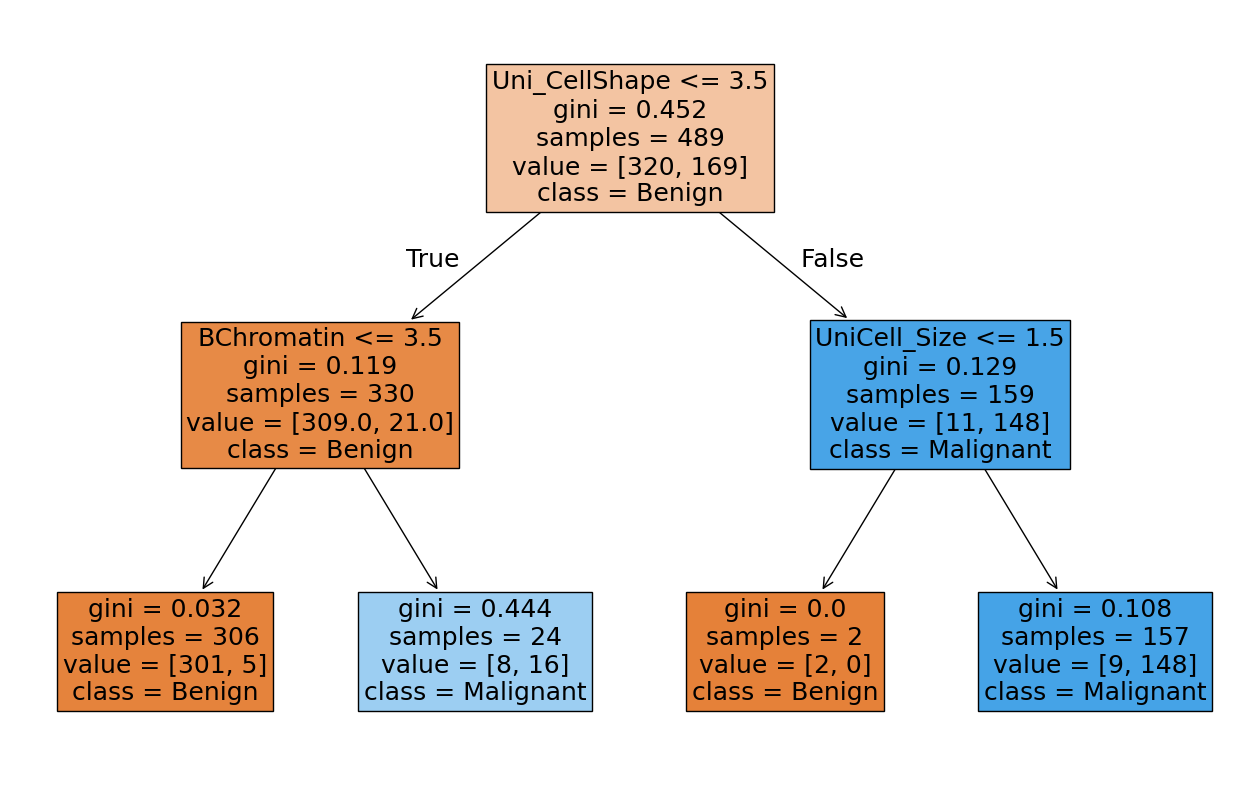

In [38]:
dtc = DecisionTreeClassifier(random_state=26,max_depth=2)
dtc.fit(X_train,y_train)
plt.figure(figsize=(16,10))
plot_tree(dtc,feature_names=list(X.columns),
          class_names=["Benign","Malignant"],
          filled=True, fontsize=18)
plt.show()

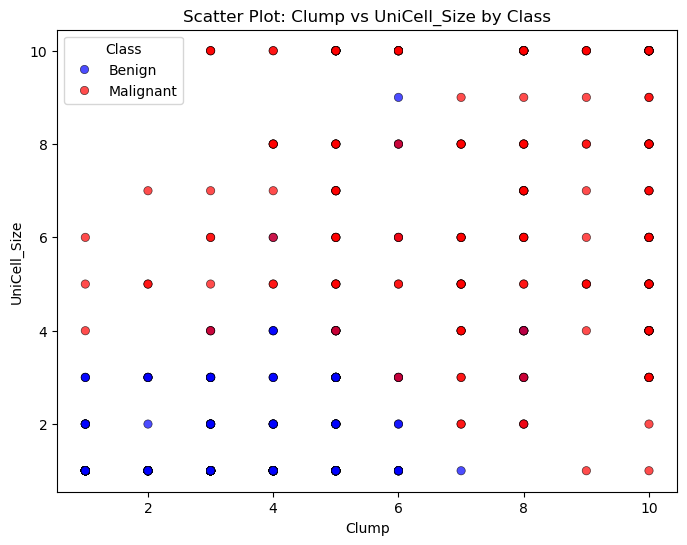

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=wisc,
    x="Clump",
    y="UniCell_Size",
    hue="Class",
    palette={"Benign": "blue", "Malignant": "red"},
    alpha=0.7,
    edgecolor="k",
)

plt.title("Scatter Plot: Clump vs UniCell_Size by Class")
plt.xlabel("Clump")
plt.ylabel("UniCell_Size")
plt.legend(title="Class")
plt.show()

<Figure size 1000x600 with 0 Axes>

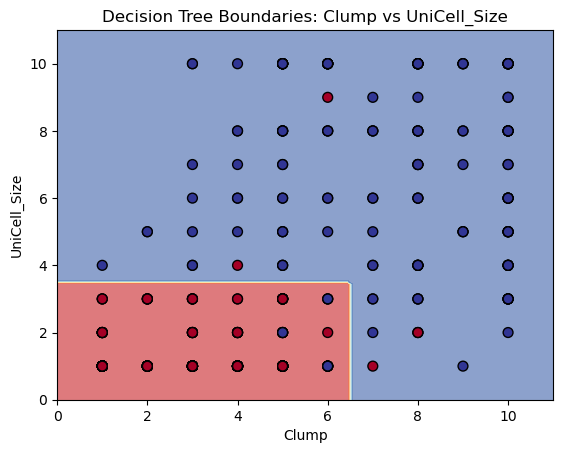

In [40]:
from sklearn.inspection import DecisionBoundaryDisplay

# 1. Choose two features to visualize in 2D space
feature_1 = "Clump"
feature_2 = "UniCell_Size"

X_2d = X_train[[feature_1, feature_2]].values

# 2. Train a Decision Tree specifically on these 2 features for plotting
dtc_2d = DecisionTreeClassifier(random_state=26, max_depth=2)
dtc_2d.fit(X_2d, y_train)

# 3. Plot the Decision Boundary and Scatter Plot
plt.figure(figsize=(10, 6))

# Render the decision regions background
DecisionBoundaryDisplay.from_estimator(
    dtc_2d,
    X_2d,
    response_method="predict",
    cmap=plt.cm.RdYlBu,
    alpha=0.6,
    xlabel=feature_1,
    ylabel=feature_2,
)

# Convert string classes ("Benign"/"Malignant") to numeric (0/1) for color mapping
y_numeric = y_train.map({"Benign": 0, "Malignant": 1})

# Overlay your scatter plot data points
scatter = plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=y_numeric,
    cmap=plt.cm.RdYlBu,
    edgecolor="k",
    s=50,
)

plt.title(f"Decision Tree Boundaries: {feature_1} vs {feature_2}")
plt.show()

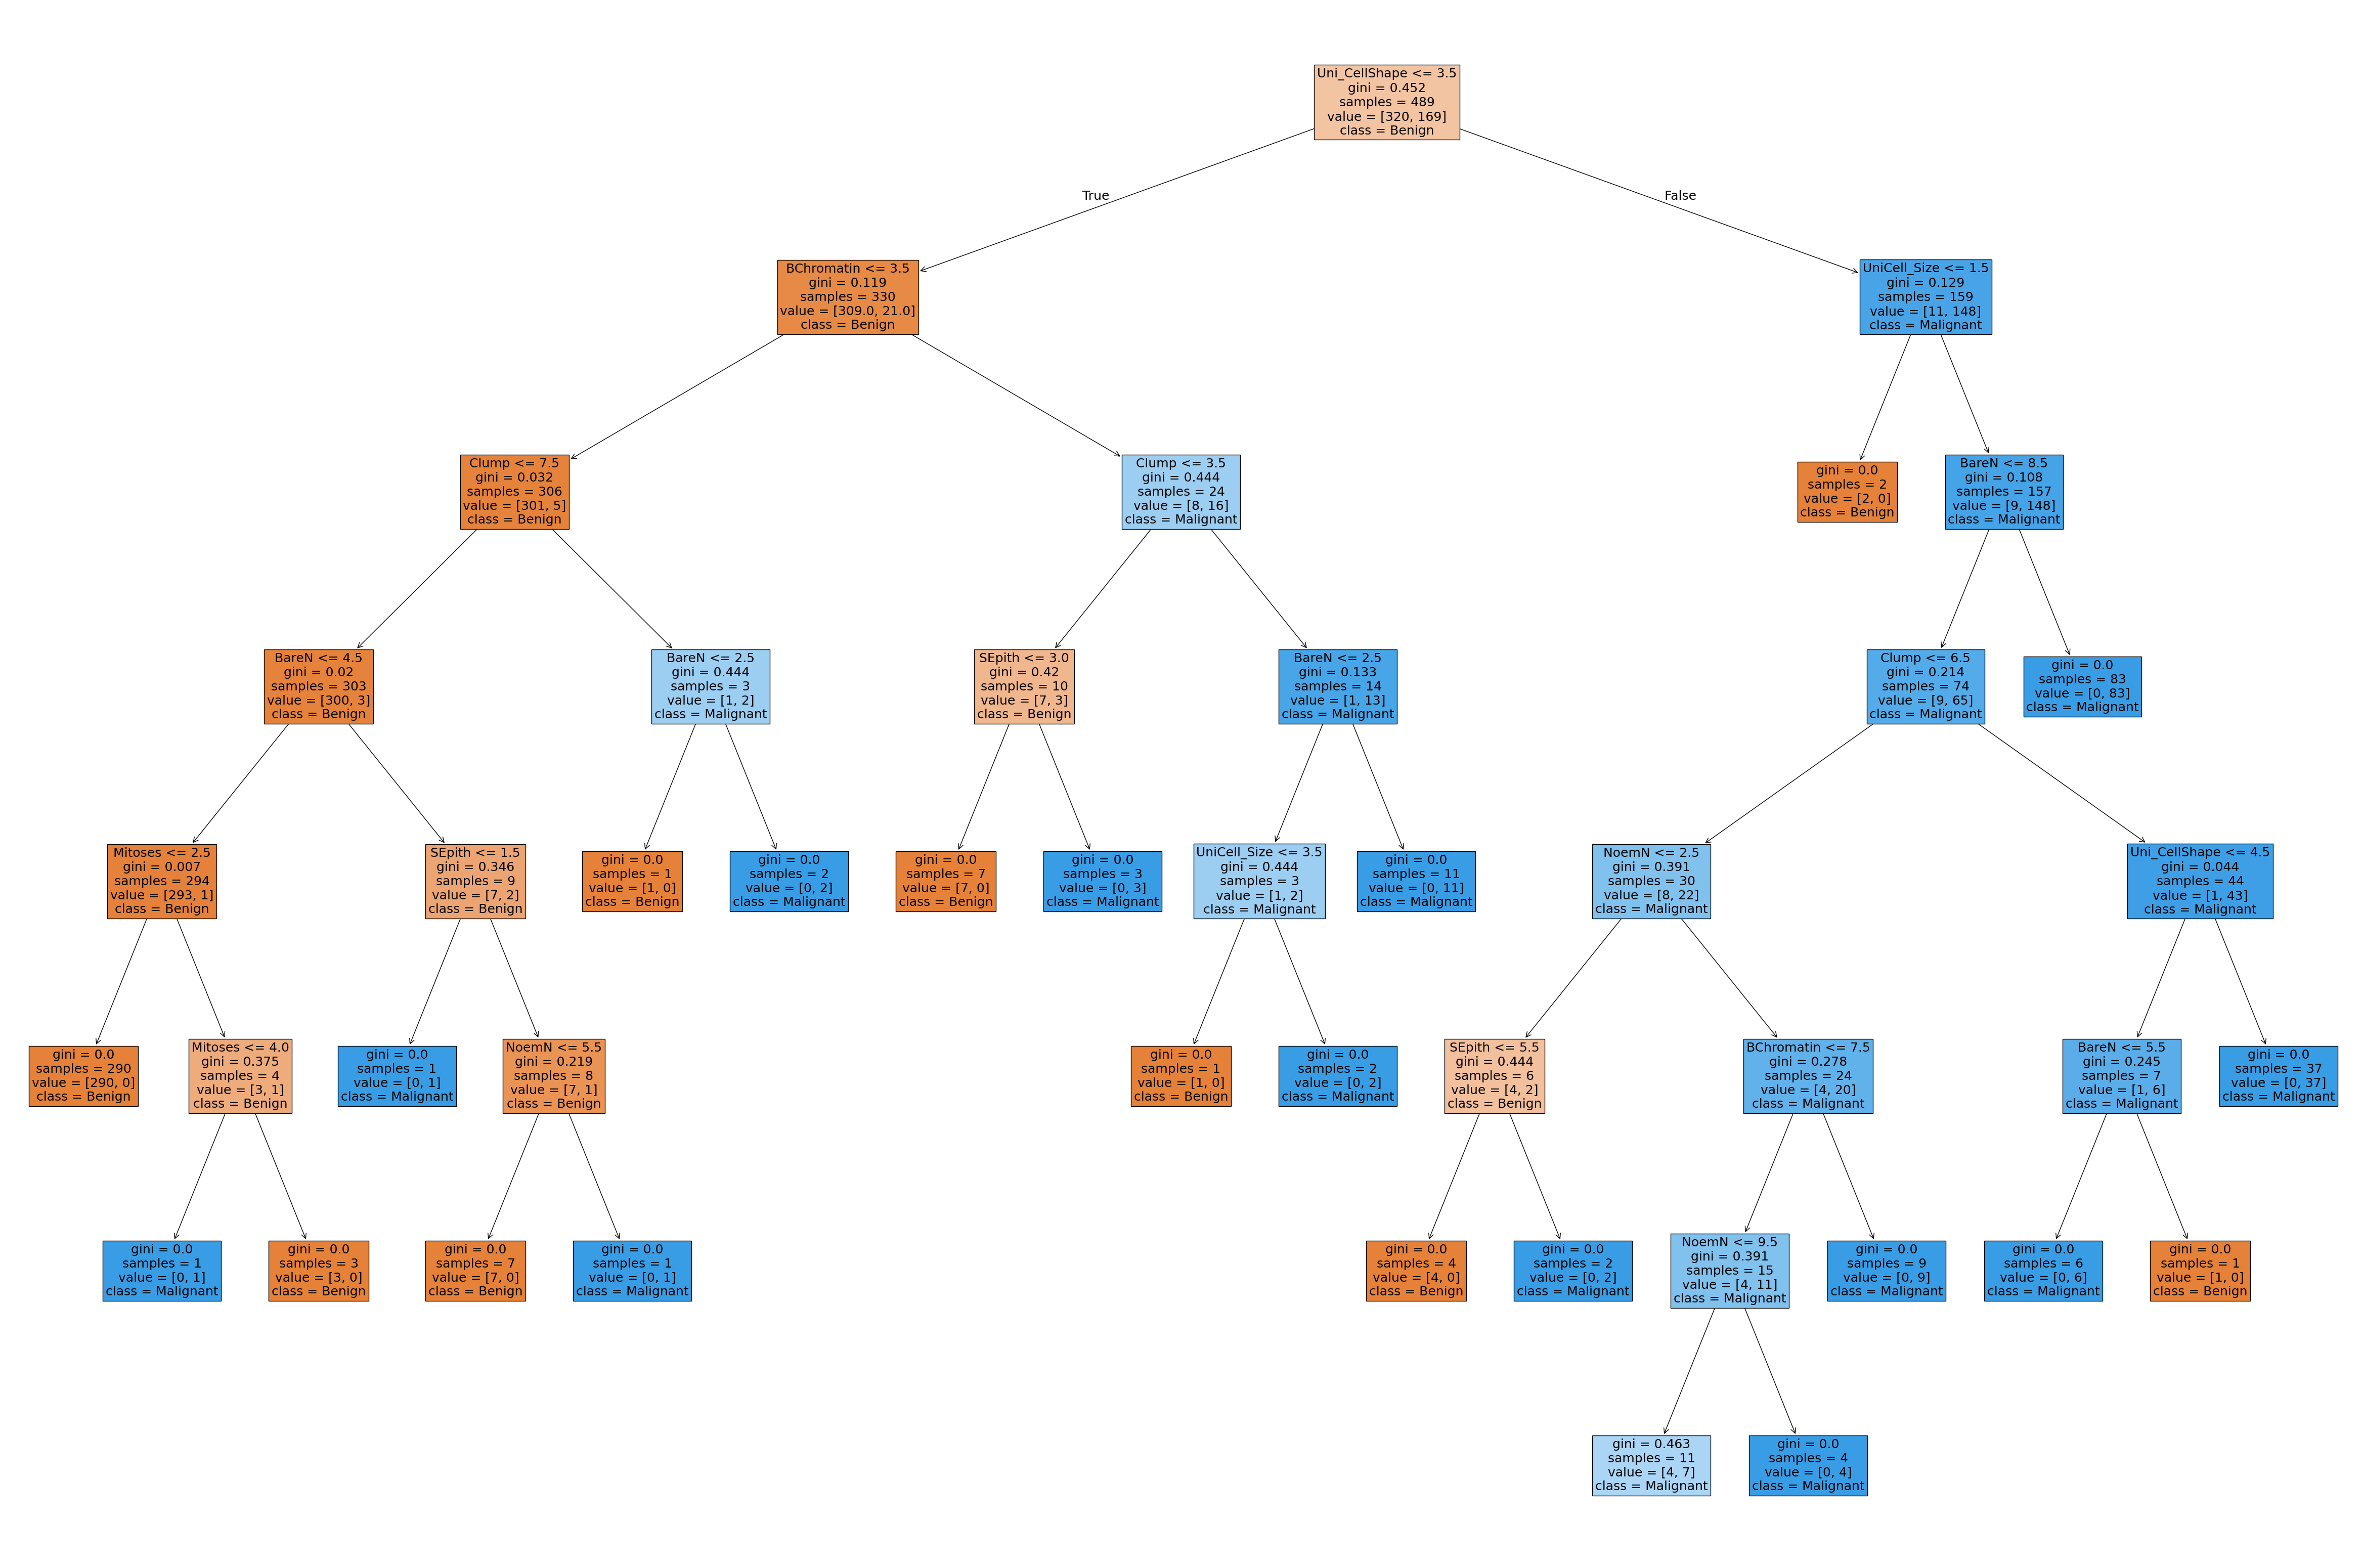

In [46]:
dtc = DecisionTreeClassifier(random_state=26,max_depth=7)
dtc.fit(X_train,y_train)
plt.figure(figsize=(60,40))
plot_tree(dtc,feature_names=list(X.columns),
          class_names=["Benign","Malignant"],
          filled=True, fontsize=18)
plt.show()

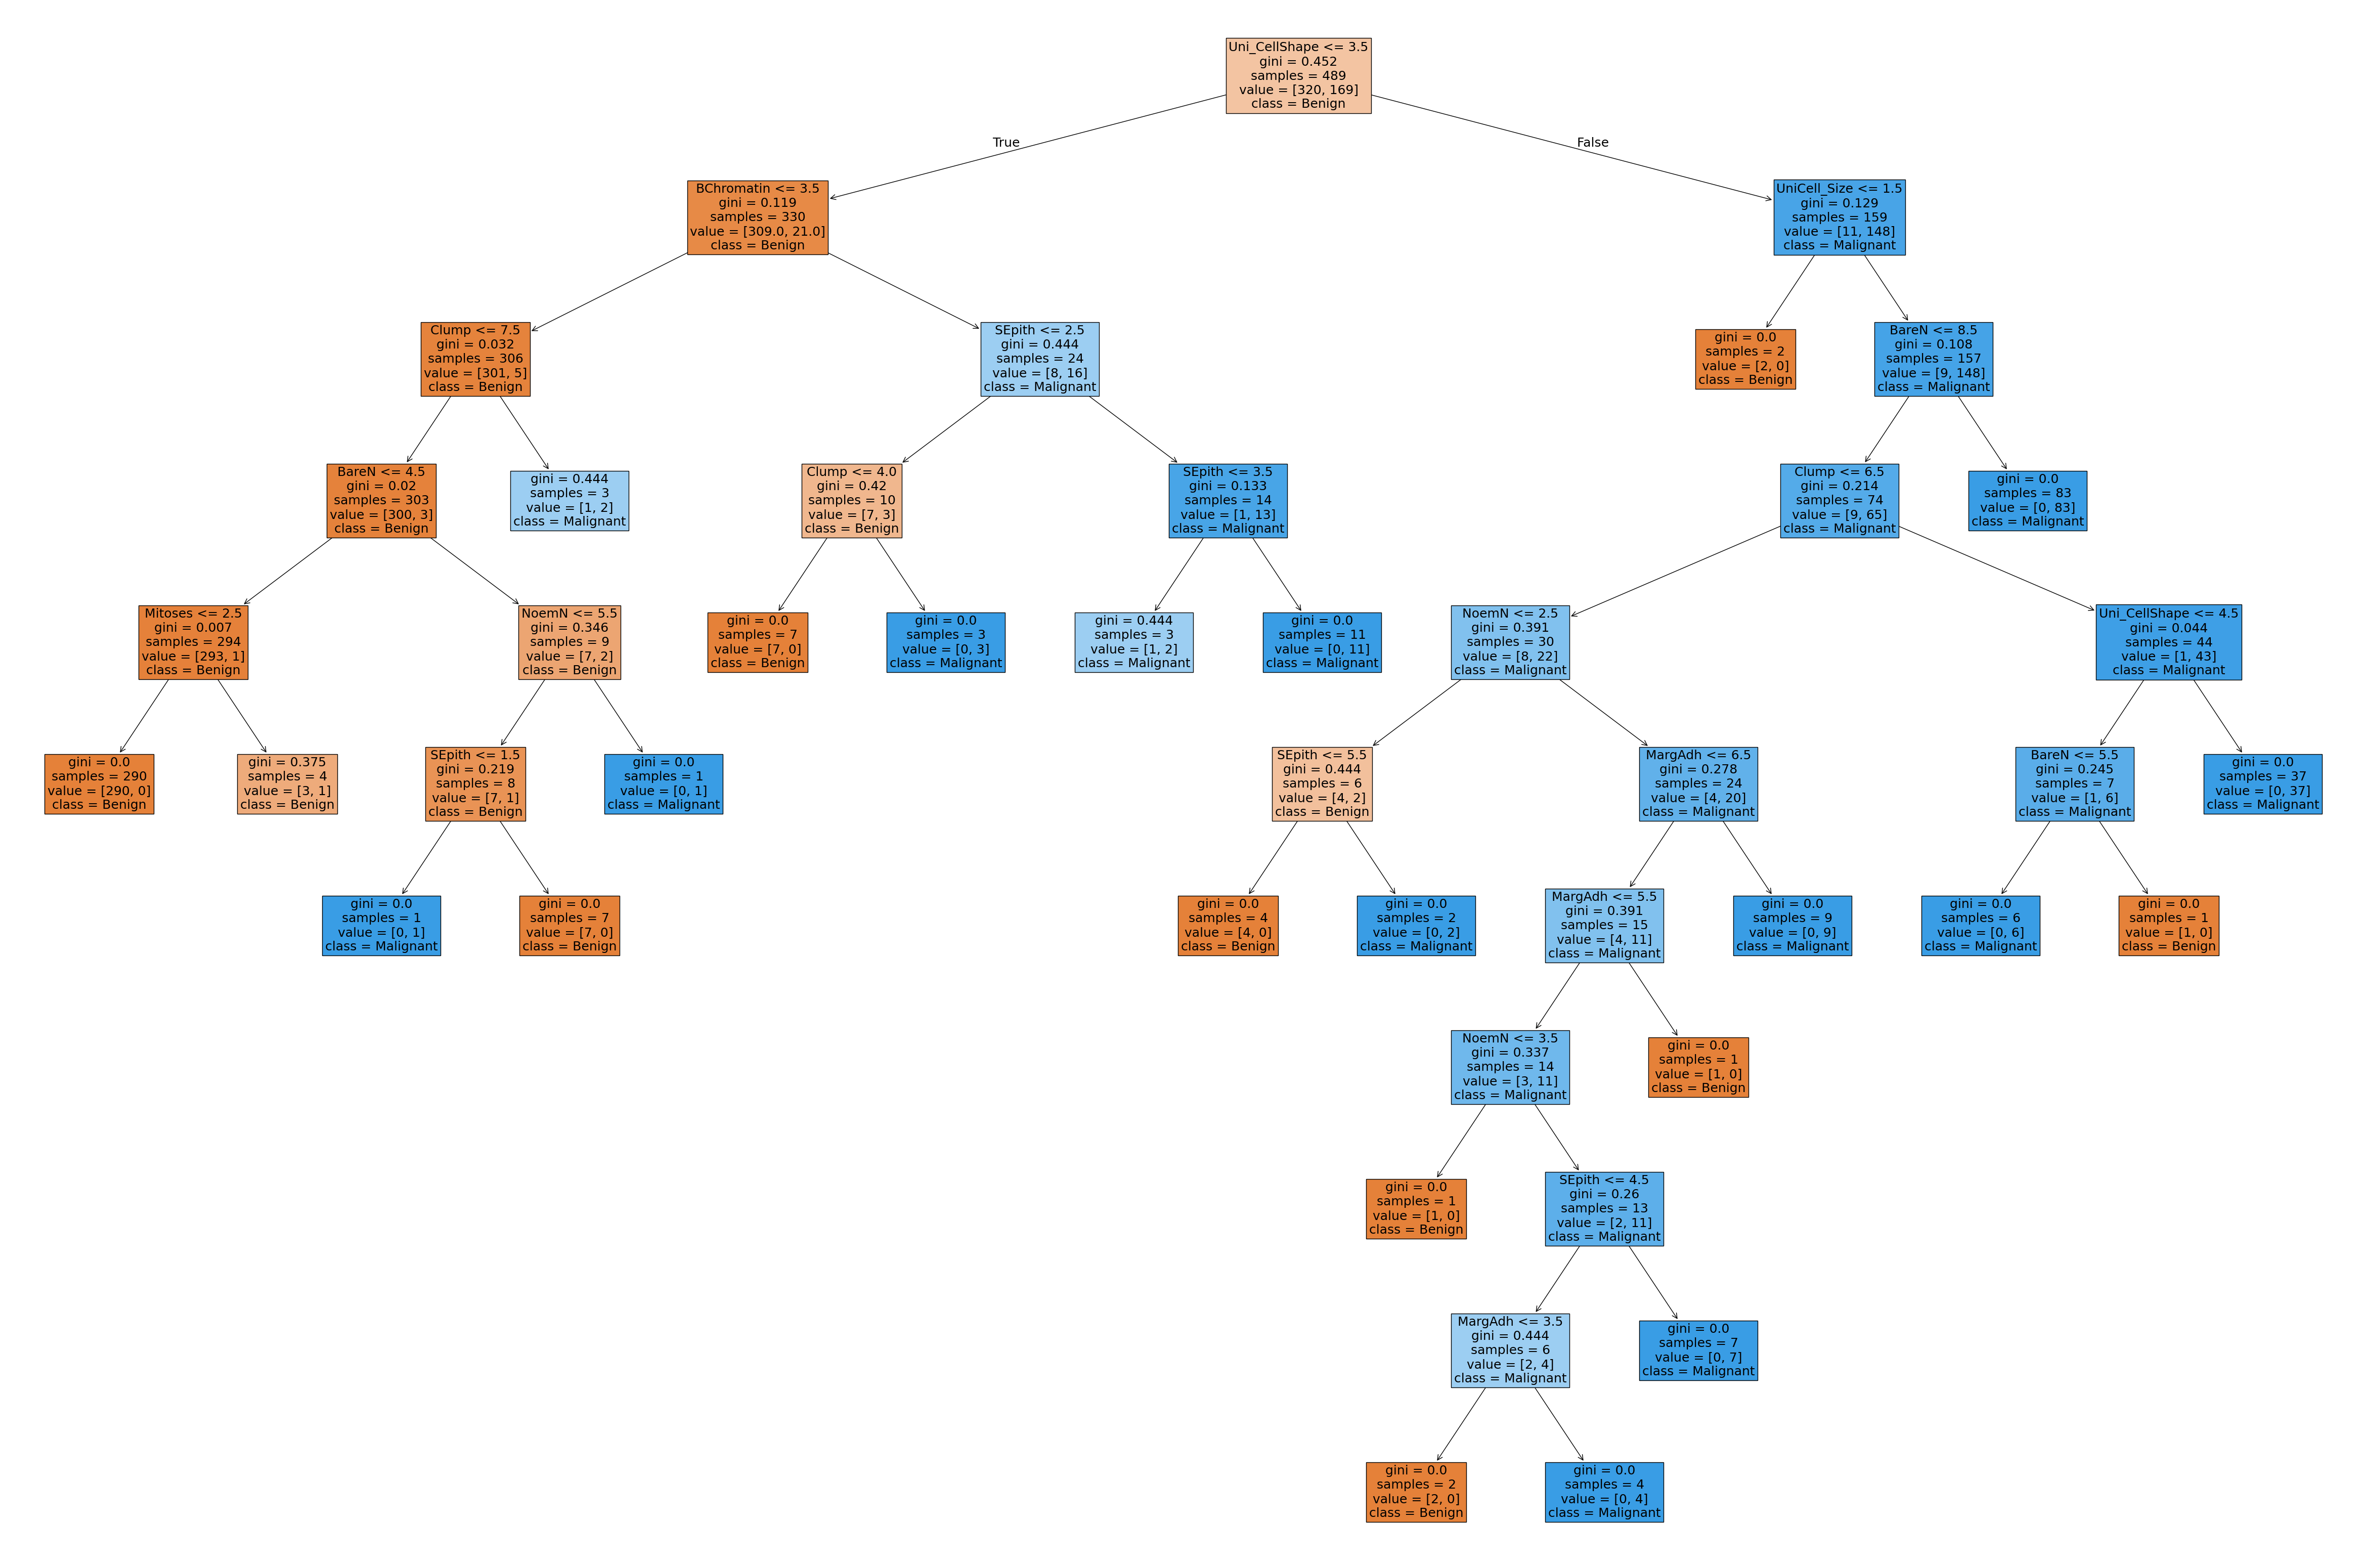

In [47]:
dtc = DecisionTreeClassifier(random_state=26,min_samples_split=5)
dtc.fit(X_train,y_train)
plt.figure(figsize=(60,40))
plot_tree(dtc,feature_names=list(X.columns),
          class_names=["Benign","Malignant"],
          filled=True, fontsize=18)
plt.show()

In [48]:
depths = [None,2,3,4,5,6,7]
min_split = [2,5,10,50]
min_leaf = [1,5,20,30,50]
scores = []
for d in depths:
    for s in min_split:
        for l in min_leaf:
            dtc = DecisionTreeClassifier(random_state=26, max_depth=d, min_samples_split=s, min_samples_leaf=l)
            dtc.fit(X_train,y_train)
            y_pred = dtc.predict(X_test)
            scores.append([d,s,l,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores, columns=["D","S","L","Scores"])
df_scores.sort_values("Scores",ascending=False)

,D,S,L,Scores
130,7.0,10,1,0.957143
10,NaN,10,1,0.957143
0,NaN,2,1,0.947619
120,7.0,2,1,0.947619
100,6.0,2,1,0.947619
...,...,...,...,...
83,5.0,2,30,0.895238
79,4.0,50,50,0.895238
78,4.0,50,30,0.895238
74,4.0,10,50,0.895238


In [ ]:
depths=[name,1,2,3,4,5.6]
min_split=[1,2,3,4,5,6,7,]
score=[]
for d in depths;
fro

HR Analytics

In [52]:
df = pd.read_csv("../Day5/HR_comma_sep.csv")
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.10,0.77,6,247,4,0,1,0,sales,low
3,0.92,0.85,5,259,5,0,1,0,sales,low
4,0.89,1.00,5,224,5,0,1,0,sales,low


In [53]:
X, y = df.drop("left", axis=1), df["left"]
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=26,test_size=0.3,stratify=y)

In [56]:
ohc = OneHotEncoder(sparse_output=False, drop="first").set_output(transform="pandas")
ct = make_column_transformer((ohc,make_column_selector(dtype_include=object)),
                             ("passthrough", make_column_selector(dtype_include=['int64','float64'])),
                             verbose_feature_names_out=False)
ct = ct_ohe.set_output(transform='pandas')

In [57]:
depths = [None,2,3,4,5,6,7]
min_split = [2,5,10,50]
min_leaf = [1,5,20,30,50]
scores = []
for d in depths:
    for s in min_split:
        for l in min_leaf:
            dtc = DecisionTreeClassifier(random_state=26, max_depth=d, min_samples_split=s, min_samples_leaf=l)
            pipe = Pipeline([("CT",ct),("TREE",dtc)])
            pipe.fit(X_train,y_train)
            y_pred = pipe.predict(X_test)
            scores.append([d,s,l,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores, columns=["D","S","L","Scores"])
df_scores.sort_values("Scores",ascending=False)

,D,S,L,Scores
125,7.0,5,1,0.978884
130,7.0,10,1,0.978884
120,7.0,2,1,0.978662
135,7.0,50,1,0.977773
15,NaN,50,1,0.976884
...,...,...,...,...
28,2.0,5,30,0.856635
29,2.0,5,50,0.856635
30,2.0,10,1,0.856635
31,2.0,10,5,0.856635


In [60]:
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('CT', ...), ('TREE', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['satisfaction_level','last_evaluation','number_project',..., 'promotion_last_5years','Department','salary']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehotencoder', ...), ('passthrough', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated th

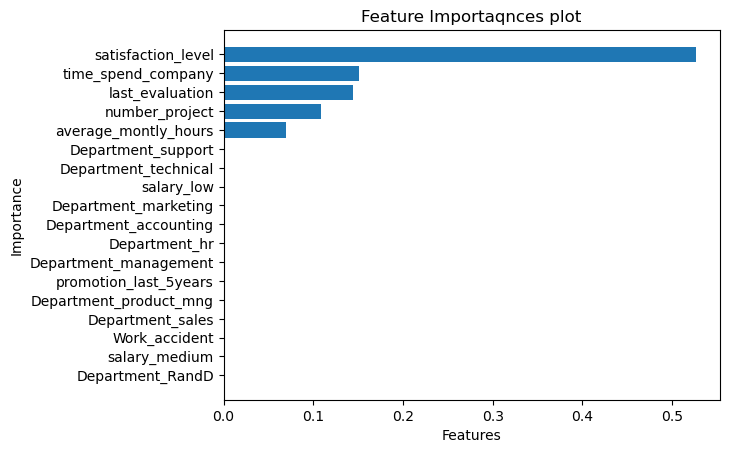

In [65]:
best_tree = DecisionTreeClassifier(random_state=26,max_depth=7,
                                  min_samples_split=5,min_samples_leaf=1)
X_ohe = ct.fit_transform(X)
best_tree.fit(X_ohe,y)
df_imp = pd.DataFrame({"features":list(X_ohe.columns),
                       "importance": best_tree.feature_importances_})
# plt.figure(figsize=(16,10))
df_imp.sort_values('importance',inplace=True)
plt.barh(df_imp["features"],df_imp["importance"])
plt.title("Feature Importaqnces plot")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.show()

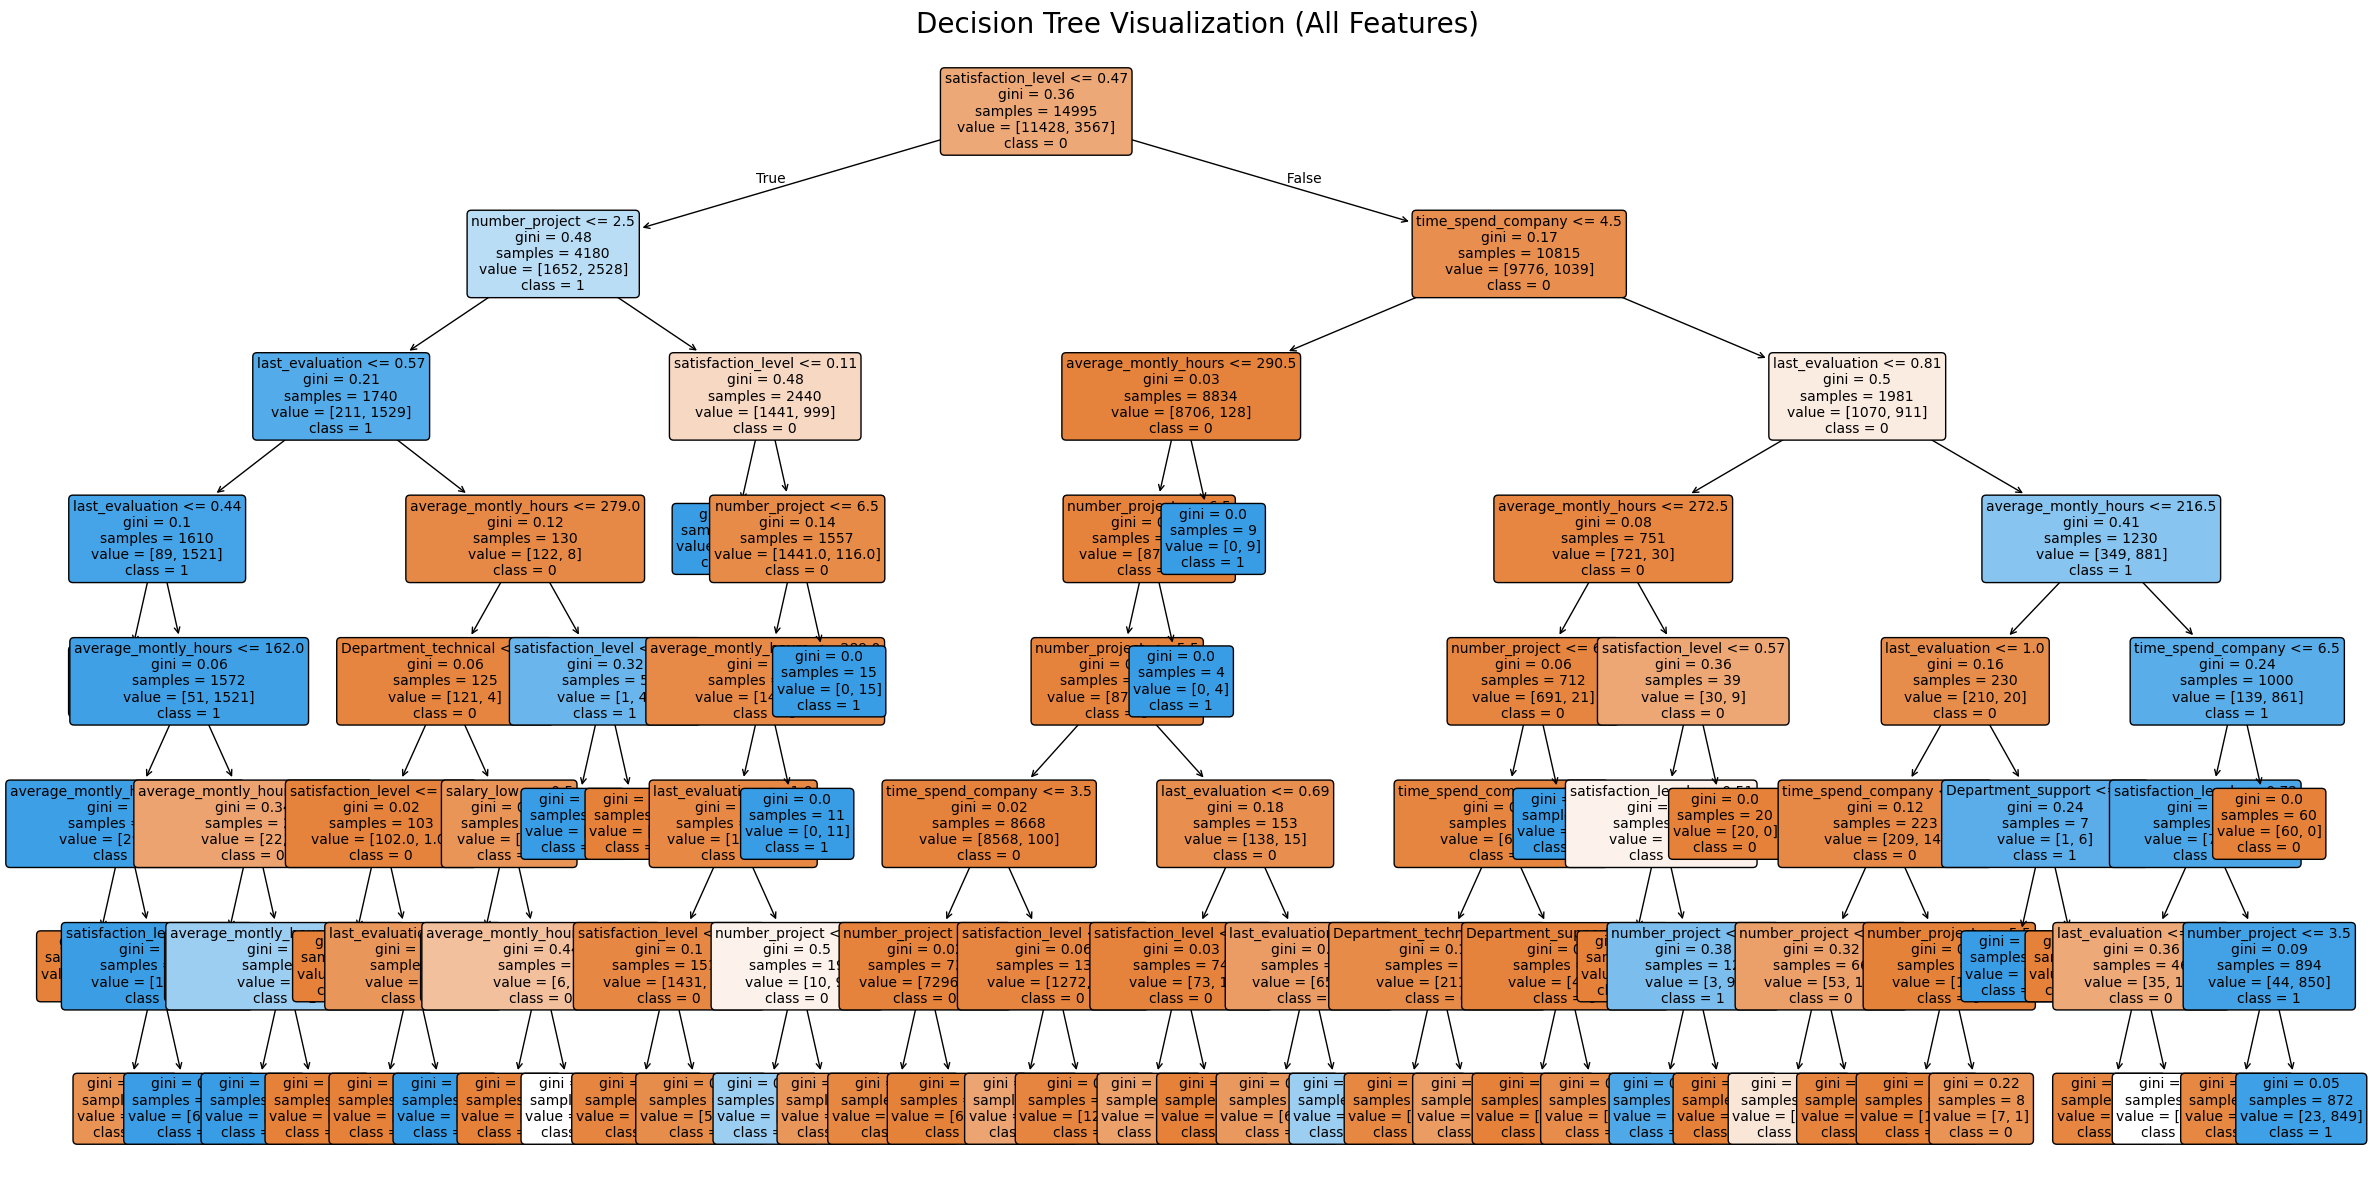

In [67]:
from sklearn.tree import plot_tree
plt.figure(figsize=(24, 12))

plot_tree(
    best_tree,  # The model you already trained
    feature_names=list(X_ohe.columns),  # Use the transformed column names
    class_names=best_tree.classes_.astype(str),  # Map numeric to class names
    filled=True,  # Color nodes by dominant class
    rounded=True,  # Beautify nodes
    fontsize=10,  # Adjust size of text inside nodes
    precision=2  # Number of decimal places for split values
)

plt.title("Decision Tree Visualization (All Features)", fontsize=20)
plt.tight_layout()
plt.show()